# **Unified Video-Text Grounding System**

# **STAGE - 0**

# *Import necessary libs*


In [ ]:
#!pip install transformers decord opencv-python tqdm torch

In [ ]:


import os
import json
import torch
import numpy as np
import cv2
import torch.nn as nn
from tqdm import tqdm
from decord import VideoReader, cpu
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from scipy.optimize import linear_sum_assignment
import torch.nn.functional as F

In [ ]:
packages = ["torch", "numpy", "cv2", "tqdm", "decord"]

for pkg in packages:
    try:
        __import__(pkg)
        print(f"{pkg} installed")
    except ImportError:
        print(f"{pkg} NOT installed")

torch installed
numpy installed
cv2 installed
tqdm installed
decord installed


In [ ]:
import torch
print(torch.__version__)

2.0.1+cu117


In [ ]:
import torch

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

Torch: 2.0.1+cu117
CUDA available: True
CUDA version: 11.7


In [ ]:
from transformers import CLIPProcessor, CLIPModel
from transformers import XCLIPModel, XCLIPProcessor

In [ ]:
print("os:", os.name)
print("json:", json.__version__ if hasattr(json, "__version__") else "built-in")
print("torch:", torch.__version__)
print("numpy:", np.__version__)
print("cv2:", cv2.__version__)
#print("tqdm:", tqdm.__version__)


os: posix
json: 2.0.9
torch: 2.0.1+cu117
numpy: 1.26.4
cv2: 4.13.0


# ***Making JSON to usable format***

In [ ]:
JSON_PATH = "/home/manasarka/Downloads/Project/activitynet_captions_train.json"
with open(JSON_PATH, 'r') as f:
    annotations_list = json.load(f)

annotations = {item['video_id']: item for item in annotations_list}
video_ids = list(annotations.keys())

print("Total videos:", len(video_ids))


Total videos: 10009


# ***Making TRAINING SAMPLES***

In [ ]:


VIDEO_DIR = "/home/manasarka/Downloads/Project/videos/Activity_Videos"

samples = []

for vid in video_ids:
    data = annotations[vid]

    base_name = data["video"].split(".")[0]

    possible_paths = [
        os.path.join(VIDEO_DIR, base_name + ".mp4"),
        os.path.join(VIDEO_DIR, base_name + ".mkv")
    ]

    video_path = None
    for path in possible_paths:
        if os.path.exists(path):
            video_path = path
            break

    if video_path is None:
        continue

    for (ts, sentence) in zip(data["timestamps"], data["sentences"]):
        start, end = ts

        samples.append({
            "video": video_path,
            "text": sentence,
            "start": start,
            "end": end,
            "duration": data["duration"]
        })

print("Total samples:", len(samples))


Total samples: 37421


In [ ]:


VIDEO_DIR = "/home/manasarka/Downloads/Project/videos/Activity_Videos"

samples = []

for vid in video_ids:
    data = annotations[vid]

    base_name = data["video"].split(".")[0]

    possible_paths = [
        os.path.join(VIDEO_DIR, base_name + ".mp4"),
        os.path.join(VIDEO_DIR, base_name + ".mkv")
    ]

    video_path = None
    for path in possible_paths:
        if os.path.exists(path):
            video_path = path
            break

    if video_path is None:
        continue

    for (ts, sentence) in zip(data["timestamps"], data["sentences"]):
        start, end = ts

        samples.append({
            "video": video_path,
            "text": sentence,
            "start": start,
            "end": end,
            "duration": data["duration"]
        })

print("Total samples:", len(samples))


Total samples: 37421


# ***VIDEO FRAME SAMPLING with fps = 2***

In [ ]:
def load_segment_frames_fps(video_path, start, end, fps_sample=2):
    vr = VideoReader(video_path, ctx=cpu(0))
    video_fps = vr.get_avg_fps()

    start_frame = int(start * video_fps)
    end_frame = int(end * video_fps)

    if end_frame <= start_frame:
        end_frame = start_frame + 1

    step = max(1, int(video_fps / fps_sample))

    indices = list(range(start_frame, end_frame, step))
    indices = np.clip(indices, 0, len(vr)-1)

    frames = vr.get_batch(indices).asnumpy()

    # resize
    frames = np.stack([cv2.resize(f, (224, 224)) for f in frames])

    return frames

# ***LOAD CLIP MODEL***

In [ ]:
device = "cuda" if torch.cuda.is_available else "cpu"



clip_md = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_pr = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

/home/manasarka/.local/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


# ***TEXT ENCODER***

In [ ]:
def encode_text(text):
    inputs = clip_pr(
        text=[text],
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    with torch.no_grad():
        #get raw transformer output
        text_outputs = clip_md.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        #take pooled output
        pooled = text_outputs.pooler_output   # [1, hidden_dim]

        #project to CLIP space
        text_features = clip_md.text_projection(pooled)

    return text_features

# ***Frame ENCODER***

In [ ]:

def encode_frames(frames):
    frames_np = [frame.permute(1, 2, 0).cpu().numpy() for frame in frames]

    inputs = clip_pr(images=frames_np, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():
        vision_outputs = clip_md.vision_model(pixel_values=pixel_values)
        pooled = vision_outputs.pooler_output
        image_features = clip_md.visual_projection(pooled)

    return image_features

# TEMPORAL AGGREGATION
## Purpose:
##      Convert multiple frames → single video embedding(avg vector)

In [ ]:
import numpy as np

def repeat_frames(frames, target_len=8):
    T = len(frames)

    if T >= target_len:
        return frames

    # repeat frames
    repeat_factor = int(np.ceil(target_len / T))

    frames = np.tile(frames, (repeat_factor, 1, 1, 1))

    return frames[:target_len]

# DATASET CLASS
## Purpose:
## Creates training samples for DataLoader

In [ ]:
from torch.utils.data import Dataset

class ActivityNetDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]

       # frames = load_segment_frames(
        frames = load_segment_frames_fps(
            item["video"],
            item["start"],
            item["end"]
        )
        #  Step 2: FIX FRAME LENGTH HERE (IMPORTANT)
        frames = repeat_frames(frames, target_len=8)

        # 🔹 Step 3: convert to tensor
        #frames = torch.tensor(frames).permute(0, 3, 1, 2).float() / 255.0
        frames = torch.tensor(frames).permute(0, 3, 1, 2).float()

        return {
            "frames": frames,
            "text": item["text"]
        }

# ***CUSTOM COLLATE FUNCTION***


In [ ]:
def collate_fn_variable(batch):
    frames_list = [item["frames"] for item in batch]
    texts = [item["text"] for item in batch]

    # find max length in batch
    max_T = max(frames.shape[0] for frames in frames_list)

    padded_frames = []

    for frames in frames_list:
        T, C, H, W = frames.shape

        if T < max_T:
            pad = torch.zeros(max_T - T, C, H, W)
            frames = torch.cat([frames, pad], dim=0)

        padded_frames.append(frames)

    frames = torch.stack(padded_frames)

    return {
        "frames": frames,   # [B, max_T, C, H, W]
        "text": texts,
        "lengths": [f.shape[0] for f in frames_list]
    }

# ***DATALOADER***

In [ ]:
from torch.utils.data import DataLoader

dataset = ActivityNetDataset(samples)

dataloader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    #collate_fn=collate_fn
    collate_fn=collate_fn_variable
)

# FEATURE EXTRACTION

# **STAGE - 1**

## BATCH VIDEO ENCODING

### Converts [B, T, C, H, W] → [B, 512]
### Encodes all frames in batch (FAST, no loop)

In [ ]:
def encode_video_batch(frames_batch):
    B, T, C, H, W = frames_batch.shape

    frames = frames_batch.view(B * T, C, H, W)
    image_features = encode_frames(frames)
    image_features = image_features.view(B, T, -1)


    video_features = image_features.mean(dim=1)

    return video_features

# BATCH TEXT ENCODING

### Converts list of texts → [B, 512]

In [ ]:
def encode_text_batch(texts):
    inputs = clip_pr(
        text=texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    text_outputs = clip_md.text_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    pooled = text_outputs.pooler_output
    text_features = clip_md.text_projection(pooled)

    return text_features

# ATTENTION POOLING

### Frame 1 → empty kitchen ❌

### Frame 2 → man holding pan ✅

### Frame 3 → chopping vegetables ✅

### Frame 4 → idle scene ❌

In [ ]:
def attention_pooling(frame_features, text_features):
    sim = torch.matmul(
        frame_features, text_features.unsqueeze(-1)
    ).squeeze(-1)  # [B, T]

    weights = F.softmax(sim, dim=1)  # [B, T]

    video_features = torch.sum(
        frame_features * weights.unsqueeze(-1), dim=1
    )

    return video_features

# ***Select top k frames***

In [ ]:
def select_topk_frames(frame_features, text_features, k=8):
    sim = torch.matmul(
        frame_features, text_features.unsqueeze(-1)
    ).squeeze(-1)  # [B, T]

    topk_idx = sim.topk(k, dim=1).indices  # [B, k]

    selected = []
    for b in range(frame_features.shape[0]):
        selected.append(frame_features[b, topk_idx[b]])

    return torch.stack(selected)  # [B, k, D]

# ***SIMILARITY MATRIX***

In [ ]:
def similarity_video_text(video_features, text_features):
  score = video_features @ text_features.T
  return score


## CONTRASTIVE LOSS

### Makes correct pairs similar
### Pushes wrong pairs apart

In [ ]:
import torch.nn.functional as F

def contrastive_loss(similarity):
    labels = torch.arange(similarity.size(0)).to(device)

    loss_v2t = F.cross_entropy(similarity, labels)
    loss_t2v = F.cross_entropy(similarity.T, labels)

    return (loss_v2t + loss_t2v) / 2

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


#  ***Traning of CLIP Model***

In [ ]:

# Step 1: Freeze all layers
for param in clip_md.parameters():
    param.requires_grad = False

# Step 2: Unfreeze selected layers
for name, param in clip_md.named_parameters():
    if "text_projection" in name or "visual.proj" in name:
        param.requires_grad = True
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, clip_md.parameters()),
    lr=1e-5
)



clip_md.train()

EPOCHS = 3
scaler = torch.cuda.amp.GradScaler()


ACCUM_STEPS = 2

for epoch in range(EPOCHS):

    total_loss = 0

    optimizer.zero_grad()   # moved outside

    for i, batch in enumerate(dataloader):

        texts = batch["text"]
        frames_batch = batch["frames"].to(device)

        with torch.cuda.amp.autocast():

            # your forward pass
            text_features = encode_text_batch(texts)

            B, T, C, H, W = frames_batch.shape
            frames = frames_batch.view(B*T, C, H, W)

            frame_features = encode_frames(frames)
            frame_features = frame_features.view(B, T, -1)

            frame_features = select_topk_frames(frame_features, text_features, k=8)
            video_features = attention_pooling(frame_features, text_features)

            video_features = video_features / video_features.norm(dim=1, keepdim=True)
            text_features = text_features / text_features.norm(dim=1, keepdim=True)

            logits = video_features @ text_features.T
            logits = logits / 0.07

            loss = contrastive_loss(logits)

            #divide loss
            loss = loss / ACCUM_STEPS


        scaler.scale(loss).backward()

        #update every ACCUM_STEPS.

        #Batch 1 → compute grad (no update)
        #Batch 2 → compute grad + update
        #Batch 3 → compute grad (no update)
        #Batch 4 → compute grad + update


        if (i + 1) % ACCUM_STEPS == 0:

            torch.nn.utils.clip_grad_norm_(clip_md.parameters(), 1.0)

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad()

        total_loss += loss.item()
        print(f"Epoch [{epoch+1}], Batch [{i}], Loss: {loss.item():.4f}")

        if i % 100 == 0:
            print(f"Epoch [{epoch+1}], Batch [{i}], Loss: {loss.item():.4f}")

    print(f"Epoch {epoch+1} Loss: {total_loss/len(dataloader):.4f}")

Epoch [1], Batch [0], Loss: 0.2187
Epoch [1], Batch [0], Loss: 0.2187
Epoch [1], Batch [1], Loss: 0.1281
Epoch [1], Batch [2], Loss: 0.2679
Epoch [1], Batch [3], Loss: 0.1615
Epoch [1], Batch [4], Loss: 0.2489
Epoch [1], Batch [5], Loss: 0.1267
Epoch [1], Batch [6], Loss: 0.2395
Epoch [1], Batch [7], Loss: 0.0927
Epoch [1], Batch [8], Loss: 0.0893
Epoch [1], Batch [9], Loss: 0.0876
Epoch [1], Batch [10], Loss: 0.0648
Epoch [1], Batch [11], Loss: 0.1023
Epoch [1], Batch [12], Loss: 0.1987
Epoch [1], Batch [13], Loss: 0.2472
Epoch [1], Batch [14], Loss: 0.0511
Epoch [1], Batch [15], Loss: 0.1532
Epoch [1], Batch [16], Loss: 0.1578
Epoch [1], Batch [17], Loss: 0.0307
Epoch [1], Batch [18], Loss: 0.0721
Epoch [1], Batch [19], Loss: 0.0765
Epoch [1], Batch [20], Loss: 0.1395
Epoch [1], Batch [21], Loss: 0.2806
Epoch [1], Batch [22], Loss: 0.0652
Epoch [1], Batch [23], Loss: 0.1697
Epoch [1], Batch [24], Loss: 0.0790
Epoch [1], Batch [25], Loss: 0.1338
Epoch [1], Batch [26], Loss: 0.0626
Epo

It looks like you are trying to rescale already rescaled images. If the input images have pixel values between 0 and 1, set `do_rescale=False` to avoid rescaling them again.


Epoch [1], Batch [92], Loss: 0.0466
Epoch [1], Batch [93], Loss: 0.1152
Epoch [1], Batch [94], Loss: 0.0779
Epoch [1], Batch [95], Loss: 0.1039
Epoch [1], Batch [96], Loss: 0.1474
Epoch [1], Batch [97], Loss: 0.1152
Epoch [1], Batch [98], Loss: 0.1012
Epoch [1], Batch [99], Loss: 0.0673
Epoch [1], Batch [100], Loss: 0.1265
Epoch [1], Batch [100], Loss: 0.1265
Epoch [1], Batch [101], Loss: 0.2932
Epoch [1], Batch [102], Loss: 0.0663
Epoch [1], Batch [103], Loss: 0.1449
Epoch [1], Batch [104], Loss: 0.1649
Epoch [1], Batch [105], Loss: 0.1750
Epoch [1], Batch [106], Loss: 0.0666
Epoch [1], Batch [107], Loss: 0.0781
Epoch [1], Batch [108], Loss: 0.1498
Epoch [1], Batch [109], Loss: 0.3836
Epoch [1], Batch [110], Loss: 0.1510
Epoch [1], Batch [111], Loss: 0.2410
Epoch [1], Batch [112], Loss: 0.0999
Epoch [1], Batch [113], Loss: 0.1786
Epoch [1], Batch [114], Loss: 0.1600
Epoch [1], Batch [115], Loss: 0.1653
Epoch [1], Batch [116], Loss: 0.0597
Epoch [1], Batch [117], Loss: 0.1993
Epoch [1]

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Epoch [2], Batch [0], Loss: 0.0868
Epoch [2], Batch [0], Loss: 0.0868
Epoch [2], Batch [1], Loss: 0.0717
Epoch [2], Batch [2], Loss: 0.0418
Epoch [2], Batch [3], Loss: 0.0040
Epoch [2], Batch [4], Loss: 0.0041
Epoch [2], Batch [5], Loss: 0.0049
Epoch [2], Batch [6], Loss: 0.0015
Epoch [2], Batch [7], Loss: 0.0022
Epoch [2], Batch [8], Loss: 0.2751
Epoch [2], Batch [9], Loss: 0.0331
Epoch [2], Batch [10], Loss: 0.0090
Epoch [2], Batch [11], Loss: 0.0164
Epoch [2], Batch [12], Loss: 0.0094
Epoch [2], Batch [13], Loss: 0.0046
Epoch [2], Batch [14], Loss: 0.0016
Epoch [2], Batch [15], Loss: 0.0019
Epoch [2], Batch [16], Loss: 0.0281
Epoch [2], Batch [17], Loss: 0.0160
Epoch [2], Batch [18], Loss: 0.0055
Epoch [2], Batch [19], Loss: 0.0012
Epoch [2], Batch [20], Loss: 0.0133
Epoch [2], Batch [21], Loss: 0.0182
Epoch [2], Batch [22], Loss: 0.0376
Epoch [2], Batch [23], Loss: 0.0018
Epoch [2], Batch [24], Loss: 0.0021
Epoch [2], Batch [25], Loss: 0.0140
Epoch [2], Batch [26], Loss: 0.0487
Epo

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Epoch [3], Batch [0], Loss: 0.0087
Epoch [3], Batch [0], Loss: 0.0087
Epoch [3], Batch [1], Loss: 0.0391
Epoch [3], Batch [2], Loss: 0.0373
Epoch [3], Batch [3], Loss: 0.3384
Epoch [3], Batch [4], Loss: 0.0053
Epoch [3], Batch [5], Loss: 0.0253
Epoch [3], Batch [6], Loss: 0.0026
Epoch [3], Batch [7], Loss: 0.0626
Epoch [3], Batch [8], Loss: 0.0106
Epoch [3], Batch [9], Loss: 0.1041
Epoch [3], Batch [10], Loss: 0.0134
Epoch [3], Batch [11], Loss: 0.0053
Epoch [3], Batch [12], Loss: 0.0016
Epoch [3], Batch [13], Loss: 0.0064
Epoch [3], Batch [14], Loss: 0.0629
Epoch [3], Batch [15], Loss: 0.1459
Epoch [3], Batch [16], Loss: 0.0049
Epoch [3], Batch [17], Loss: 0.0017
Epoch [3], Batch [18], Loss: 0.0016
Epoch [3], Batch [19], Loss: 0.0019
Epoch [3], Batch [20], Loss: 0.0041
Epoch [3], Batch [21], Loss: 0.0045
Epoch [3], Batch [22], Loss: 0.0242
Epoch [3], Batch [23], Loss: 0.0039
Epoch [3], Batch [24], Loss: 0.0046
Epoch [3], Batch [25], Loss: 0.0095
Epoch [3], Batch [26], Loss: 0.0007
Epo

# ***Save CLIP Model***

In [ ]:
torch.save(clip_md.state_dict(), "stage1_clip_m.pht")

# STAGE - 2

In [ ]:
from scipy.optimize import linear_sum_assignment

In [ ]:

FEATURE_DIR = "./clip_features"
os.makedirs(FEATURE_DIR, exist_ok=True)


In [ ]:
def load_segment_frames(video_path, start, end, fps_sample=2):
    vr = VideoReader(video_path, ctx=cpu(0))
    video_fps = vr.get_avg_fps()

    start_frame = int(start * video_fps)
    end_frame = int(end * video_fps)

    if end_frame <= start_frame:
        end_frame = start_frame + 1

    step = max(1, int(video_fps / fps_sample))

    indices = list(range(start_frame, end_frame, step))
    indices = np.clip(indices, 0, len(vr)-1)

    frames = vr.get_batch(indices).asnumpy()

    # resize
    frames = np.stack([cv2.resize(f, (224, 224)) for f in frames])

    return frames

In [ ]:
def encode_frames(frames):
    # frames: numpy array [T, H, W, C]

    inputs = clip_pr(
        images=list(frames),  # list of numpy images
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():
        vision_outputs = clip_md.vision_model(pixel_values=pixel_values)
        pooled = vision_outputs.pooler_output
        image_features = clip_md.visual_projection(pooled)

    return image_features  # [T, 512]

In [ ]:
def encode_text_batch(texts):
    inputs = clip_pr(
        text=texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    text_outputs = clip_md.text_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    pooled = text_outputs.pooler_output
    text_features = clip_md.text_projection(pooled)

    return text_features

In [ ]:
def extract_features(samples):

    for i, sample in enumerate(tqdm(samples)):

        try:
            #array [T, H, W, C]
            frames = load_segment_frames(
                sample["video"], 0, sample["duration"]
            )

            if len(frames) == 0:
                continue


            video_feat = encode_frames(frames)   # [T, 512]

            text_feat = encode_text_batch([sample["text"]])[0]


            video_feat = video_feat / video_feat.norm(dim=-1, keepdim=True)
            text_feat  = text_feat / text_feat.norm()

            #center-width GT
            s = sample["start"] / sample["duration"]
            e = sample["end"] / sample["duration"]

            c = (s + e) / 2
            w = (e - s)

            gt = torch.tensor([c, w], dtype=torch.float32)

            torch.save({
                "video": video_feat.cpu(),
                "text": text_feat.cpu(),
                "gt": gt
            }, os.path.join(FEATURE_DIR, f"{i}.pt"))

        except Exception as e:
            print(f"Error at sample {i}:", e)

In [ ]:
import os
import torch
import numpy as np
import cv2
from tqdm import tqdm
from decord import VideoReader, cpu

# 1. Config
device = "cuda" if torch.cuda.is_available() else "cpu"
FEATURE_DIR = "./clip_features_1"
LOG_FILE = "failed_samples.txt"
FPS_SAMPLE = 2

os.makedirs(FEATURE_DIR, exist_ok=True)


#EXTRACTION LOOP
def extract_features(samples):
    # Delete old log
    if os.path.exists(LOG_FILE):
        os.remove(LOG_FILE)

    existing = set(os.listdir(FEATURE_DIR))
    success, failed = 0, 0


    def safe_encode_frames(frames):
        try:
            inputs = clip_pr(images=list(frames), return_tensors="pt")
            pixel_values = inputs["pixel_values"].to(device)
            with torch.no_grad():
                outputs = clip_md.vision_model(pixel_values=pixel_values)
                feats = clip_md.visual_projection(outputs.pooler_output)
            if torch.isnan(feats).any(): return None
            return feats
        except Exception:
            return None

    def safe_encode_text(text):
        try:
            inputs = clip_pr(text=[text], return_tensors="pt", padding=True, truncation=True).to(device)
            with torch.no_grad():
                outputs = clip_md.text_model(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"])
                feats = clip_md.text_projection(outputs.pooler_output)
            if torch.isnan(feats).any(): return None
            return feats[0]
        except Exception:
            return None

    def safe_load_frames(video_path, start, end):
        try:
            vr = VideoReader(video_path, ctx=cpu(0))
            fps = vr.get_avg_fps()
            start_f = int(start * fps)
            end_f = int(end * fps)
            if end_f <= start_f: end_f = start_f + 1

            step = max(1, int(fps / FPS_SAMPLE))
            indices = list(range(start_f, end_f, step))
            indices = np.clip(indices, 0, len(vr)-1)

            if len(indices) == 0: return None
            if len(indices) > 300: indices = np.linspace(indices[0], indices[-1], 300).astype(int)

            frames = vr.get_batch(indices).asnumpy()
            return np.stack([cv2.resize(f, (224, 224)) for f in frames])
        except Exception:
            return None

    # START LOOP
    print("Extracting features (This may take a while)...")
    for i, sample in enumerate(tqdm(samples)):
        fname = f"{i}.pt"
        if fname in existing:
            success += 1
            continue

        try:
            frames = safe_load_frames(sample["video"], 0, sample["duration"])
            if frames is None: raise ValueError("Frame load failed (File might be missing or corrupt)")

            video_feat = safe_encode_frames(frames)
            if video_feat is None: raise ValueError("Video encoding failed")

            text_feat = safe_encode_text(sample["text"])
            if text_feat is None: raise ValueError("Text encoding failed")

            # L2 Normalize
            video_feat = video_feat / (video_feat.norm(dim=-1, keepdim=True) + 1e-6)
            text_feat  = text_feat / (text_feat.norm() + 1e-6)

            # Ground truth relative format
            s = sample["start"] / sample["duration"]
            e = sample["end"] / sample["duration"]
            gt = torch.tensor([(s+e)/2, (e-s)], dtype=torch.float32)

            torch.save({"video": video_feat.cpu(), "text": text_feat.cpu(), "gt": gt}, os.path.join(FEATURE_DIR, fname))
            success += 1

        except Exception as e:
            failed += 1
            with open(LOG_FILE, "a") as f:
                f.write(f"{i}: {str(e)}\n")

    print(f" Extracted & Saved: {success}")
    print(f" Failed: {failed}")

# Execute!
extract_features(samples)


Extracting features (This may take a while)...


  0%|                                      | 6/37421 [00:08<14:41:26,  1.41s/it]


KeyboardInterrupt: 

In [ ]:
#  DATASET & COLLATE (SUPPORT MULTIPLE GTs)
class FeatureDataset(torch.utils.data.Dataset):
    def __init__(self, path):
        self.files = [f for f in os.listdir(path) if f.endswith('.pt')]
        self.path = path

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        d = torch.load(os.path.join(self.path, self.files[idx]))

        # Ensure GT is always 2D [num_gts, 2] even if it only has 1 target
        gt = d["gt"]
        if gt.dim() == 1:
            gt = gt.view(-1, 2)

        return d["video"], d["text"], gt

In [ ]:

def collate_fn(batch):
    vids, texts, gts = zip(*batch)
    max_T = max(v.shape[0] for v in vids)

    padded_vids = []
    masks = []
    for v in vids:
        pad_len = max_T - v.shape[0]
        pad = torch.zeros(pad_len, 512)
        padded_vids.append(torch.cat([v, pad], dim=0))

        # True = Padding (Ignore in Attention)
        mask = torch.cat([torch.zeros(v.shape[0], dtype=torch.bool),
                          torch.ones(pad_len, dtype=torch.bool)])
        masks.append(mask)

    # Note: `gts` is returned natively as a LIST, since shape might be [1,2] or [3,2]
    return torch.stack(padded_vids), torch.stack(texts), list(gts), torch.stack(masks)

In [ ]:
#  ARCHITECTURE (FUSION + QDDETR)
class SinePositionalEncoding1D(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x):
        seq_len = x.size(1)
        return x + self.pe[:, :seq_len, :]

class TextVideoFusion(nn.Module):
    """ Query-Dependent Fusion: Makes video features explicitly aware of the text """
    def __init__(self, dim=512):
        super().__init__()
        self.v_proj = nn.Linear(dim, dim)
        self.t_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim))

    def forward(self, vf, tf):
        tf_expanded = tf.unsqueeze(1) # [B, 1, D]
        gate = torch.sigmoid(self.t_proj(tf_expanded))
        fused = self.v_proj(vf) * gate
        return self.out_proj(fused + vf)

class QDDETR(nn.Module):
    def __init__(self, dim=512, num_queries=20):
        super().__init__()
        self.num_queries = num_queries

        self.query_embed = nn.Embedding(num_queries, dim)
        self.pos_encoder = SinePositionalEncoding1D(dim)
        self.fusion = TextVideoFusion(dim)

        self.transformer = nn.Transformer(
            d_model=dim, nhead=8, num_encoder_layers=4, num_decoder_layers=4, batch_first=True
        )

        self.box = nn.Linear(dim, 2)
        self.score = nn.Linear(dim, 1)

    def forward(self, vf, tf, padding_mask):
        B = vf.shape[0]

        vf = self.pos_encoder(vf)
        src = self.fusion(vf, tf) # [B, T, 512] -> True Query-Dependency!

        decoder_queries = self.query_embed.weight.unsqueeze(0).repeat(B, 1, 1)

        # Feed into transformer natively (no text appending means mask is unmodified)
        hs = self.transformer(src=src, tgt=decoder_queries, src_key_padding_mask=padding_mask)

        # Boxes get sigmoid. Logits stay raw for BCE loss stability!
        boxes = torch.sigmoid(self.box(hs))
        logits = self.score(hs)

        return boxes, logits

In [ ]:
#  DETR MATH & FULL LOSS
def box_cxw_to_start_end(x):
    center, duration = x.unbind(-1)
    return torch.stack([center - 0.5 * duration, center + 0.5 * duration], dim=-1)

def pairwise_generalized_box_iou_1d(boxes1, boxes2):
    """ Pairwise IoU between predicted [N, 2] and targets [M, 2] """
    b1 = box_cxw_to_start_end(boxes1).unsqueeze(1) # [N, 1, 2]
    b2 = box_cxw_to_start_end(boxes2).unsqueeze(0) # [1, M, 2]

    inter_min = torch.max(b1[..., 0], b2[..., 0])
    inter_max = torch.min(b1[..., 1], b2[..., 1])
    inter = (inter_max - inter_min).clamp(min=0)

    union = (b1[..., 1] - b1[..., 0]) + (b2[..., 1] - b2[..., 0]) - inter
    iou = inter / union

    enclose_min = torch.min(b1[..., 0], b2[..., 0])
    enclose_max = torch.max(b1[..., 1], b2[..., 1])
    enclose = (enclose_max - enclose_min).clamp(min=1e-6)

    return iou - (enclose - union) / enclose

class HungarianMatcher1D(nn.Module):
    def __init__(self, cost_class=1.0, cost_bbox=5.0, cost_giou=2.0):
        super().__init__()
        self.cost_class, self.cost_bbox, self.cost_giou = cost_class, cost_bbox, cost_giou

    @torch.no_grad()
    def forward(self, pred_logits, pred_boxes, targets):
        bs = pred_logits.shape[0]
        indices = []
        for b in range(bs):
            prob = pred_logits[b].sigmoid()  # [num_queries, 1]

            bbox = pred_boxes[b]  # [num_queries, 2]
            tgt = targets[b]      # [num_gts, 2]

            # Pairwise distance matrix [num_queries, num_gts]
            c_class = -prob.repeat(1, tgt.shape[0])
            c_bbox = torch.cdist(bbox, tgt, p=1)
            c_giou = -pairwise_generalized_box_iou_1d(bbox, tgt)

            C = self.cost_class * c_class + self.cost_bbox * c_bbox + self.cost_giou * c_giou

            row_ind, col_ind = linear_sum_assignment(C.cpu().numpy())
            indices.append((torch.as_tensor(row_ind, dtype=torch.int64), torch.as_tensor(col_ind, dtype=torch.int64)))

        return indices

class SetCriterion1D(nn.Module):
    def __init__(self, matcher, weight_dict):
        super().__init__()
        self.matcher = matcher
        self.weight_dict = weight_dict

    def forward(self, pred_logits, pred_boxes, targets):
        indices = self.matcher(pred_logits, pred_boxes, targets)

        batch_idx = torch.cat([torch.full_like(src, i) for i, (src, _) in enumerate(indices)])
        src_idx = torch.cat([src for (src, _) in indices])

        # 1. Classification Loss (All queries pushed towards 0, matched ones pushed to 1)
        src_logits_flat = pred_logits.squeeze(-1)
        target_classes = torch.zeros_like(src_logits_flat)
        target_classes[batch_idx, src_idx] = 1.0
        loss_ce = F.binary_cross_entropy_with_logits(src_logits_flat, target_classes)

        # 2. Bounding Box & GIoU Loss (Applied ONLY to matched queries)
        src_boxes_matched = pred_boxes[batch_idx, src_idx]
        tgt_boxes_matched = torch.cat([t[j] for t, (_, j) in zip(targets, indices)], dim=0)

        loss_bbox = F.l1_loss(src_boxes_matched, tgt_boxes_matched)
        loss_giou = 1 - torch.diag(pairwise_generalized_box_iou_1d(src_boxes_matched, tgt_boxes_matched))

        total_loss = (self.weight_dict['loss_ce'] * loss_ce +
                      self.weight_dict['loss_bbox'] * loss_bbox +
                      self.weight_dict['loss_giou'] * loss_giou.mean())

        return total_loss



In [ ]:
import math
device = "cuda" if torch.cuda.is_available() else "cpu"
FEATURE_DIR = "./clip_features"

In [ ]:
import math
from tqdm import tqdm

if os.path.exists(FEATURE_DIR) and len(os.listdir(FEATURE_DIR)) > 0:

    dataset = FeatureDataset(FEATURE_DIR)
    loader  = torch.utils.data.DataLoader(dataset, batch_size=8, shuffle=True, collate_fn=collate_fn)

    model     = QDDETR(dim=512, num_queries=20).to(device)
    matcher   = HungarianMatcher1D(cost_class=1.0, cost_bbox=5.0, cost_giou=2.0)
    criterion = SetCriterion1D(
                    matcher,
                    weight_dict={'loss_ce': 2.0, 'loss_bbox': 5.0, 'loss_giou': 2.0}
                ).to(device)

    #  Higher LR + less restrictive clipping
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100, eta_min=1e-6)

    print("Starting Training Loop...")
    best_loss = float("inf")

    for epoch in range(100):
        model.train()
        total_loss = 0

        pbar = tqdm(loader, desc=f"Epoch {epoch+1:03d}", leave=True)
        for batch_idx, (vf, tf, gts, mask) in enumerate(pbar):
            vf, tf, mask = vf.to(device), tf.to(device), mask.to(device)
            gts = [gt.to(device) for gt in gts]

            optimizer.zero_grad()
            pred_boxes, pred_logits = model(vf, tf, padding_mask=mask)
            loss = criterion(pred_logits, pred_boxes, gts)
            loss.backward()

            # max_norm=1.0 (standard for transformers, not 0.1)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        scheduler.step()
        avg_loss = total_loss / len(loader)
        print(f"Epoch {epoch+1:03d} | Loss = {avg_loss:.4f} | LR = {scheduler.get_last_lr()[0]:.2e}")

        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(model.state_dict(), "qd_detr_model_v3.pth")

        if avg_loss < 0.30:
            print(f" Converged at epoch {epoch+1}!")
            break

    print(f"\nBest loss: {best_loss:.4f} — saved to qd_detr_model_v3.pth")

else:
    print("Skipping: No .pt files found")


Starting Training Loop...


Epoch 001: 100%|███████████████| 4678/4678 [04:47<00:00, 16.27it/s, loss=1.8053]


Epoch 001 | Loss = 1.8485 | LR = 3.00e-04


Epoch 002: 100%|███████████████| 4678/4678 [04:56<00:00, 15.77it/s, loss=1.6292]


Epoch 002 | Loss = 1.6652 | LR = 3.00e-04


Epoch 003: 100%|███████████████| 4678/4678 [04:58<00:00, 15.69it/s, loss=1.6370]


... (93 outputs left out)

Epoch 050: 100%|███████████████| 4678/4678 [04:49<00:00, 16.18it/s, loss=1.7562]


Epoch 050 | Loss = 1.4467 | LR = 1.50e-04


Epoch 051:  19%|███             | 907/4678 [00:56<03:53, 16.14it/s, loss=1.6648]


KeyboardInterrupt: 

In [ ]:

VAL1_JSON = "/home/manasarka/Downloads/Project/activitynet_captions_val1.json"

with open(VAL1_JSON) as f:
    val1_list = json.load(f)

val1_annotations = {item['video_id']: item for item in val1_list}
val1_samples = []
for vid, data in val1_annotations.items():
    base = data["video"].split(".")[0]
    vpath = None
    for ext in [".mp4", ".mkv"]:
        p = os.path.join(VIDEO_DIR, base + ext)
        if os.path.exists(p):
            vpath = p; break
    if not vpath: continue
    for ts, sentence in zip(data["timestamps"], data["sentences"]):
        val1_samples.append({
            "video": vpath, "text": sentence,
            "start": ts[0], "end": ts[1], "duration": data["duration"]
        })

print(f"val_1 samples: {len(val1_samples)}")

val_1 samples: 17505


In [ ]:
import math

In [ ]:
# =============================================
#  STAGE - VALIDATION & INFERENCE
# =============================================


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ── Fine-tuned CLIP ───────────────────────────────────────────
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_model.load_state_dict(torch.load(
    "/home/manasarka/Downloads/Project/stage1_clip_m.pht",
    map_location=DEVICE
))
clip_model.to(DEVICE).eval()
clip_pr = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print(" Fine-tuned CLIP loaded")

# ── QD-DETR architecture (must match training) ────────────────
class SinePositionalEncoding1D(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class TextVideoFusion(nn.Module):
    def __init__(self, dim=512):
        super().__init__()
        self.v_proj   = nn.Linear(dim, dim)
        self.t_proj   = nn.Linear(dim, dim)
        self.out_proj = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim))
    def forward(self, vf, tf):
        gate = torch.sigmoid(self.t_proj(tf.unsqueeze(1)))
        return self.out_proj(self.v_proj(vf) * gate + vf)

class QDDETR(nn.Module):
    def __init__(self, dim=512, num_queries=20):
        super().__init__()
        self.query_embed = nn.Embedding(num_queries, dim)
        self.pos_encoder = SinePositionalEncoding1D(dim)
        self.fusion      = TextVideoFusion(dim)
        self.transformer = nn.Transformer(
            d_model=dim, nhead=8,
            num_encoder_layers=4, num_decoder_layers=4,
            batch_first=True
        )
        self.box   = nn.Linear(dim, 2)
        self.score = nn.Linear(dim, 1)
    def forward(self, vf, tf, padding_mask):
        B   = vf.shape[0]
        vf  = self.pos_encoder(vf)
        src = self.fusion(vf, tf)
        tgt = self.query_embed.weight.unsqueeze(0).repeat(B, 1, 1)
        hs  = self.transformer(src=src, tgt=tgt,
                               src_key_padding_mask=padding_mask)
        return torch.sigmoid(self.box(hs)), self.score(hs)

detr_model = QDDETR(dim=512, num_queries=20).to(DEVICE)
detr_model.load_state_dict(torch.load(
    "/home/manasarka/Downloads/Project/qd_detr_model_v3.pth",
    map_location=DEVICE
))
detr_model.eval()
print(" QD-DETR loaded")
print(f"Device: {DEVICE}")


 Fine-tuned CLIP loaded
 QD-DETR loaded
Device: cuda


In [ ]:
# CLIP sliding window → threshold union ────────────
@torch.no_grad()
def clip_filter_union(video_path, query, clip_threshold, window=4, overlap=2):
    vr       = VideoReader(video_path, ctx=cpu(0))
    fps      = vr.get_avg_fps()
    duration = len(vr) / fps
    step     = window - overlap

    txt_inp = clip_pr(text=[query], return_tensors="pt",
                      padding=True, truncation=True).to(DEVICE)
    tf = F.normalize(clip_model.get_text_features(**txt_inp), dim=-1).squeeze(0)

    passing = []
    t = 0.0
    while t + window <= duration:
        sf      = int(t * fps)
        ef      = int((t + window) * fps)
        idx     = np.linspace(sf, ef-1, 8).astype(int).clip(0, len(vr)-1)
        frames  = vr.get_batch(idx).asnumpy()
        img_inp = clip_pr(images=list(frames), return_tensors="pt").to(DEVICE)
        vf      = F.normalize(clip_model.get_image_features(**img_inp), dim=-1).mean(0)
        if (vf @ tf).item() >= clip_threshold:
            passing.append((t, t + window))
        t += step

    if not passing:
        return None, None, duration

    return min(s for s, e in passing), max(e for s, e in passing), duration



In [ ]:
#----------------------Metric Helpers--------------------
def iou_1d(pred_s, pred_e, gt_s, gt_e):
    inter = max(0.0, min(pred_e, gt_e) - max(pred_s, gt_s))
    union = max(pred_e, gt_e) - min(pred_s, gt_s)
    return inter / union if union > 0 else 0.0

def compute_metrics(results):
    ious  = [r["iou"]   for r in results]
    found = [r["found"] for r in results]
    n = len(results)
    return {
        "R@1_IoU0.3":  sum(1 for i in ious if i >= 0.3) / n,
        "R@1_IoU0.5":  sum(1 for i in ious if i >= 0.5) / n,
        "R@1_IoU0.7":  sum(1 for i in ious if i >= 0.7) / n,
        "mIoU":        round(float(np.mean(ious)), 4),
        "hit_rate":      round(float(np.mean(found)), 4),
        "n_evaluated": n
    }


In [ ]:
#--------------Load val_1 + CLIP Threshold Search--------------


# ── Load val_1 ────────────────────────────────────────────────
VAL1_JSON = "/home/manasarka/Downloads/Project/activitynet_captions_val1.json"
VIDEO_DIR = "/home/manasarka/Downloads/Project/videos/Activity_Videos"

with open(VAL1_JSON) as f:
    val1_list = json.load(f)

val1_annotations = {item['video_id']: item for item in val1_list}
val1_samples = []
for vid, data in val1_annotations.items():
    base = data["video"].split(".")[0]
    vpath = None
    for ext in [".mp4", ".mkv"]:
        p = os.path.join(VIDEO_DIR, base + ext)
        if os.path.exists(p):
            vpath = p; break
    if not vpath: continue
    for ts, sentence in zip(data["timestamps"], data["sentences"]):
        val1_samples.append({
            "video": vpath, "text": sentence,
            "start": ts[0], "end": ts[1], "duration": data["duration"]
        })

print(f"val_1 samples: {len(val1_samples)}")

# ── CLIP threshold search ─────────────────────────────────────
@torch.no_grad()
def eval_clip_threshold(samples, clip_thr, n_eval=400, window=4, overlap=2):
    results = []
    for s in tqdm(samples[:n_eval], desc=f"CLIP={clip_thr:.2f}", leave=False):
        try:
            u_s, u_e, dur = clip_filter_union(s["video"], s["text"],
                                               clip_thr, window, overlap)
            if u_s is None:
                results.append({"iou": 0.0, "found": False}); continue
            results.append({"iou": iou_1d(u_s, u_e, s["start"], s["end"]),
                            "found": True})
        except Exception:
            results.append({"iou": 0.0, "found": False})
    return compute_metrics(results)

clip_thresholds = [0.10, 0.12, 0.14, 0.16, 0.17, 0.18, 0.20, 0.22, 0.25]
clip_results    = {}

for ct in clip_thresholds:
    m = eval_clip_threshold(val1_samples, ct, n_eval=400)
    clip_results[ct] = m
    print(f"CLIP={ct:.2f} | R@0.3={m['R@1_IoU0.3']:.3f} | "
          f"R@0.5={m['R@1_IoU0.5']:.3f} | R@0.7={m['R@1_IoU0.7']:.3f} | "
          f"mIoU={m['mIoU']:.3f} | Recall={m['recall']:.3f}")

best_clip_thr = max(clip_results, key=lambda t: clip_results[t]["R@1_IoU0.5"])
print(f"\n Best CLIP threshold: {best_clip_thr}")


val_1 samples: 17505


CLIP=0.10 | R@0.3=0.422 | R@0.5=0.240 | R@0.7=0.128 | mIoU=0.322 | Recall=0.985


CLIP=0.12 | R@0.3=0.430 | R@0.5=0.240 | R@0.7=0.133 | mIoU=0.322 | Recall=0.978


CLIP=0.14 | R@0.3=0.422 | R@0.5=0.253 | R@0.7=0.133 | mIoU=0.318 | Recall=0.965


CLIP=0.16 | R@0.3=0.427 | R@0.5=0.247 | R@0.7=0.140 | mIoU=0.317 | Recall=0.943


CLIP=0.17 | R@0.3=0.417 | R@0.5=0.250 | R@0.7=0.135 | mIoU=0.314 | Recall=0.930


CLIP=0.18 | R@0.3=0.410 | R@0.5=0.250 | R@0.7=0.128 | mIoU=0.306 | Recall=0.917


CLIP=0.20 | R@0.3=0.405 | R@0.5=0.258 | R@0.7=0.130 | mIoU=0.303 | Recall=0.887


CLIP=0.22 | R@0.3=0.388 | R@0.5=0.237 | R@0.7=0.128 | mIoU=0.286 | Recall=0.848


CLIP=0.25 | R@0.3=0.352 | R@0.5=0.207 | R@0.7=0.110 | mIoU=0.255 | Recall=0.760

 Best CLIP threshold: 0.2


In [ ]:

VAL_JSON = "/home/manasarka/Downloads/Project/activitynet_captions_val_2.json"

with open(VAL_JSON) as f:
    val2_list = json.load(f)

val2_samples = []

for data in val2_list:
    base = data["video"].split(".")[0]

    vpath = None
    for ext in [".mp4", ".mkv"]:
        p = os.path.join(VIDEO_DIR, base + ext)
        if os.path.exists(p):
            vpath = p
            break

    if not vpath:
        continue

    for ts, sentence in zip(data["timestamps"], data["sentences"]):
        val2_samples.append({
            "video": vpath,
            "text": sentence,
            "start": ts[0],
            "end": ts[1],
            "duration": data["duration"]
        })

print(f"val_2 samples: {len(val2_samples)}")

val_2 samples: 16926


In [ ]:
print(f"val_2 samples: {len(val2_samples)}")

results = []

for s in val2_samples[:300]:
    try:
        u_s, u_e, _ = clip_filter_union(s["video"], s["text"], 0.2)

        if u_s is None:
            results.append({"iou": 0.0, "found": False})
            continue

        p_s, p_e = qddetr_predict(s["video"], s["text"], u_s, u_e)

        results.append({
            "iou": iou_1d(p_s, p_e, s["start"], s["end"]),
            "found": True
        })

    except Exception as e:
        print("ERROR:", e)
        results.append({"iou": 0.0, "found": False})


val2_final = compute_metrics(results)

print("\n" + "="*52)
print("  FINAL RESULTS — val_2")
print("="*52)
print(f"  R@1 IoU=0.3 : {val2_final['R@1_IoU0.3']:.4f}")
print(f"  R@1 IoU=0.5 : {val2_final['R@1_IoU0.5']:.4f}")
print(f"  R@1 IoU=0.7 : {val2_final['R@1_IoU0.7']:.4f}")
print(f"  mIoU        : {val2_final['mIoU']:.4f}")
print("="*52)

val_2 samples: 16926

  FINAL RESULTS — val_2
  R@1 IoU=0.3 : 0.7733
  R@1 IoU=0.5 : 0.4833
  R@1 IoU=0.7 : 0.0967
  mIoU        : 0.4371


# IoU Distribution (Histogram)

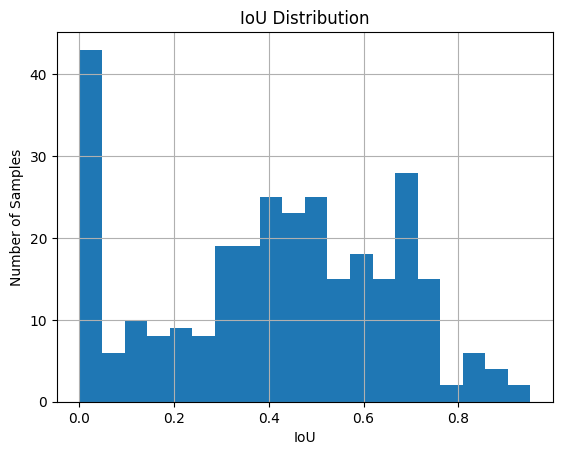

In [ ]:
import matplotlib.pyplot as plt

ious = [r["iou"] for r in results]

plt.figure()
plt.hist(ious, bins=20)
plt.xlabel("IoU")
plt.ylabel("Number of Samples")
plt.title("IoU Distribution")
plt.grid()

plt.show()

# Recall vs IoU Threshold Curve

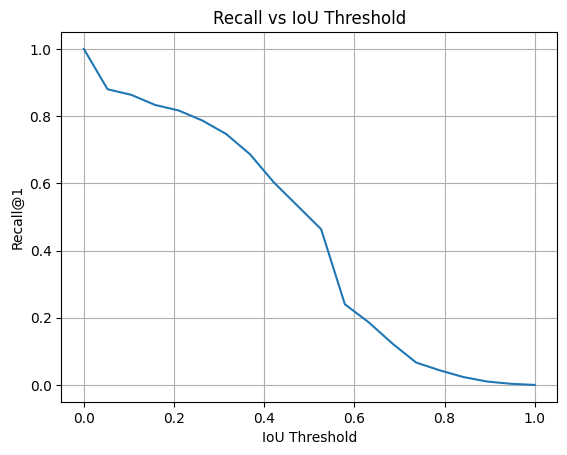

In [ ]:
import numpy as np

thresholds = np.linspace(0, 1, 20)
recalls = []

for t in thresholds:
    recall = sum(1 for i in ious if i >= t) / len(ious)
    recalls.append(recall)

plt.figure()
plt.plot(thresholds, recalls)
plt.xlabel("IoU Threshold")
plt.ylabel("Recall@1")
plt.title("Recall vs IoU Threshold")
plt.grid()

plt.show()

# Success vs Failure Pie Chart

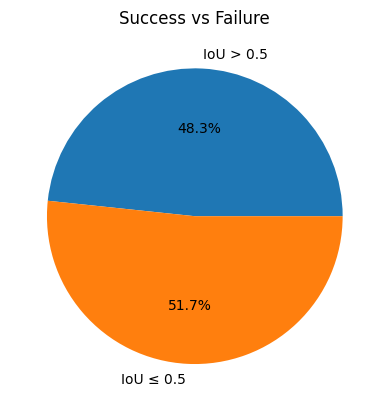

In [ ]:
success = sum(1 for i in ious if i >= 0.5)
failure = len(ious) - success

plt.figure()
plt.pie([success, failure], labels=["IoU > 0.5", "IoU ≤ 0.5"], autopct='%1.1f%%')
plt.title("Success vs Failure")

plt.show()

# IoU Range Distribution (Bar Plot)

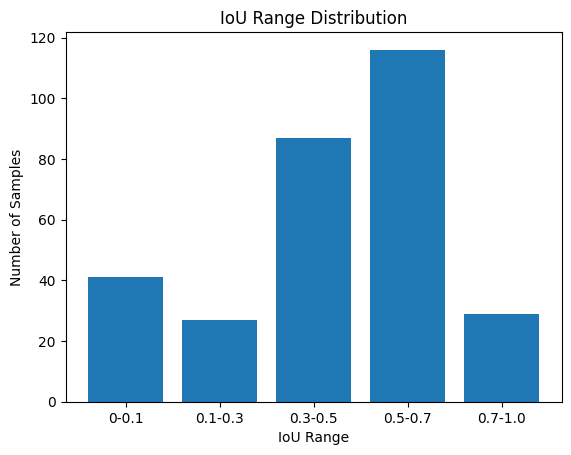

In [ ]:
import matplotlib.pyplot as plt

ious = [r["iou"] for r in results]

plt.figure()
plt.hist(ious, bins=20)
plt.xlabel("IoU")
plt.ylabel("Number of Samples")
plt.title("IoU Distribution")
plt.grid()

plt.show()

# IoU Range Comparison

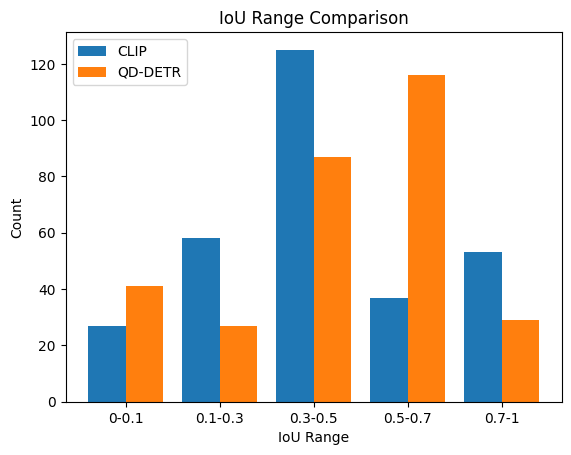

In [ ]:
import matplotlib.pyplot as plt

qd_ious = [r["iou"] for r in results]

plt.figure()
plt.hist(clip_ious, bins=20, alpha=0.5, label="CLIP")
plt.hist(qd_ious, bins=20, alpha=0.5, label="QD-DETR")

plt.xlabel("IoU")
plt.ylabel("Count")
plt.title("CLIP vs QD-DETR IoU Distribution")
plt.legend()
plt.grid()

plt.show()

In [ ]:
import math

In [ ]:
##--------------- QD-DETR Inference Diagnostic

# ── Step 0: Load trained QD-DETR ──
qddetr_model = QDDETR(dim=512, num_queries=20).to(DEVICE)
qddetr_model.load_state_dict(torch.load("qd_detr_model_v2.pth", map_location=DEVICE))
qddetr_model.eval()
print("QD-DETR loaded")

# ── Step 1: Define Inference Function ──
@torch.no_grad()
def qddetr_predict(video_path, query, cand_s, cand_e, n_frames=32):
    """Predict precise timestamps within candidate segment [cand_s, cand_e]."""
    vr  = VideoReader(video_path, ctx=cpu(0))
    fps = vr.get_avg_fps()
    dur = cand_e - cand_s
    if dur <= 0:
        return cand_s, cand_e

    # ── Video features from candidate segment ──
    sf  = int(cand_s * fps)
    ef  = int(cand_e * fps)
    idx = np.linspace(sf, ef - 1, n_frames).astype(int).clip(0, len(vr) - 1)
    frames = vr.get_batch(idx).asnumpy()  # [n_frames, H, W, 3]

    imgs = clip_pr(images=list(frames), return_tensors="pt").to(DEVICE)
    vf   = clip_model.get_image_features(**imgs)           # [n_frames, 512]
    vf   = vf / vf.norm(dim=-1, keepdim=True)
    vf   = vf.unsqueeze(0)                                 # [1, n_frames, 512]

    # ── Text features ──
    txt  = clip_pr(text=[query], return_tensors="pt",
                   padding=True, truncation=True).to(DEVICE)
    tf   = clip_model.get_text_features(**txt)             # [1, 512]
    tf   = tf / tf.norm(dim=-1, keepdim=True)
   # tf   = tf.unsqueeze(1)                                 # [1, 1, 512]

    # ── Padding mask (no padding needed) ──
    mask = torch.zeros(1, n_frames, dtype=torch.bool).to(DEVICE)

    # ── Forward pass ──
    pred_boxes, pred_logits = qddetr_model(vf, tf, padding_mask=mask)
    # pred_boxes:   [1, num_queries, 2]  → (center, width) normalized [0,1]
    # pred_logits:  [1, num_queries, C]

    # ── Select best query (highest foreground probability) ──
    if pred_logits.shape[-1] >= 2:
        scores = pred_logits[0, :, 1]   # foreground class score
    else:
        scores = pred_logits[0, :, 0]

    best  = scores.argmax().item()
    center, width = pred_boxes[0, best].clamp(0, 1).tolist()

    # ── Convert normalized → absolute timestamps ──
    pred_s = cand_s + (center - width / 2) * dur
    pred_e = cand_s + (center + width / 2) * dur

    # Clamp to candidate bounds
    pred_s = float(np.clip(pred_s, cand_s, cand_e))
    pred_e = float(np.clip(pred_e, cand_s, cand_e))

    if pred_e <= pred_s:          # degenerate box → fallback
        return cand_s, cand_e

    return pred_s, pred_e


# ── Step 2: 5-Sample Diagnostic ──
print("\n" + "="*60)
print("  QD-DETR 5-SAMPLE DIAGNOSTIC")
print("="*60)

for i, s in enumerate(val2_samples[0:10]):
    print(f"\n[Sample {i+1}] Query: {s['text'][:60]}")
    print(f"  GT:      {s['start']:.1f}s → {s['end']:.1f}s")
    try:
        u_s, u_e, _ = clip_filter_union(s["video"], s["text"], 0.2)
        if u_s is None:
            print("  CLIP:    No segment found"); continue
        print(f"  CLIP:    {u_s:.1f}s → {u_e:.1f}s")

        p_s, p_e = qddetr_predict(s["video"], s["text"], u_s, u_e)
        print(f"  QD-DETR: {p_s:.1f}s → {p_e:.1f}s")

        iou_clip   = iou_1d(u_s, u_e, s["start"], s["end"])
        iou_qddetr = iou_1d(p_s, p_e, s["start"], s["end"])
        print(f"  IoU:  CLIP={iou_clip:.3f} | QDDETR={iou_qddetr:.3f}")

    except Exception as e:
        import traceback; traceback.print_exc()


QD-DETR loaded

  QD-DETR 5-SAMPLE DIAGNOSTIC

[Sample 1] Query: One man is holding onto a rope attached to a machine, and th
  GT:      4.1s → 33.4s
  CLIP:    0.0s → 54.0s
  QD-DETR: 15.8s → 52.6s
  IoU:  CLIP=0.541 | QDDETR=0.363

[Sample 2] Query: The man then instructs the man holding the rope to pull the 
  GT:      33.4s → 55.1s
  CLIP:    0.0s → 54.0s
  QD-DETR: 15.8s → 52.6s
  IoU:  CLIP=0.374 | QDDETR=0.489

[Sample 3] Query: Three men are standing on a mat.
  GT:      6.9s → 69.1s
  CLIP:    16.0s → 72.0s
  QD-DETR: 32.3s → 70.6s
  IoU:  CLIP=0.816 | QDDETR=0.577

[Sample 4] Query: The man in front begins to do karate on the mat.
  GT:      37.3s → 43.5s
  CLIP:    16.0s → 72.0s
  QD-DETR: 32.3s → 70.6s
  IoU:  CLIP=0.111 | QDDETR=0.162

[Sample 5] Query: He gets down on the ground and flips around.
  GT:      43.1s → 55.5s
  CLIP:    42.0s → 72.0s
  QD-DETR: 50.8s → 71.2s
  IoU:  CLIP=0.414 | QDDETR=0.171

[Sample 6] Query: A young lady is gripping a black and silver punchi